# Causes of high NO$_2$:CO enhancement ratios during the Eaton and Palisades Fires

In [1]:
import cartopy.crs as ccrs
from enum import IntEnum
from functools import partial
import geopandas as gpd
from jllutils import miscutils
import jllutils.plots as jplt
from loguru import logger
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.patches import ConnectionPatch
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import numpy as np
import pandas as pd
import rasterio
from shapely import Geometry, Polygon
import sys
import tomllib

import pynbcode.aerosols as nbaer
import pynbcode.carb as nbcarb
import pynbcode.constants as nbcst
import pynbcode.enhancement_ratios as nber
import pynbcode.er_frp_analysis as nberf
import pynbcode.gridded_data as nbgrid
import pynbcode.plots as nbplt
import pynbcode.plot_utils as nbpu
import pynbcode.structures as nbstruct
import pynbcode.utils as nbutils

import pynbcode.tropess.tropess_data as nbtrdat

In [2]:
sys.path.append('static-data/tropomi-custom/')

In [3]:
import make_custom_l2

pyephem not installed, solar noon functions will not work


In [4]:
logger.remove()
logger.add(sys.stderr, level='INFO')

1

## Load common data

In [5]:
with open('static-data/download-config-small.toml', 'rb') as f:
    la_cfg = tomllib.load(f)

with open('static-data/download-config-anderson.toml', 'rb') as f:
    anderson_cfg = tomllib.load(f)

In [6]:
structure_damage_gdf = nbstruct.load_structures_damage_df()

In [7]:
goes_frp = nberf.GoesFrpProvider('static-data/goes/eaton_and_palisades-la_basin-goes_summary.nc')
goes_west_coast_frp = nberf.GoesMultiSceneFrpProvider('static-data/goes/')
modis_terra_frp = nberf.ModisFrpProvider('static-data/modis/terra/')
viirs_jpss2_frp = nberf.ViirsFrpProvider('static-data/viirs/jpss-2/fire_nrt_J2V-C2_all_jan.json')
viirs_west_coast_frp = nberf.ViirsMultiJsonFrpProvider(
    'static-data/viirs/jpss-1/fire_archive_J1V-2020_west_coast.json',
    'static-data/viirs/jpss-1/fire_archive_J1V-2021_west_coast.json',
)
perimeters_gdf = gpd.read_file('static-data/fire-progression/fire-perimeters.geojson')

static-data/modis/terra/MOD14.A2025007.0535.061.2025007083453.hdf has no fires
static-data/modis/terra/MOD14.A2025007.0540.061.2025007083540.hdf has no fires
static-data/modis/terra/MOD14.A2025010.0600.061.2025010150018.hdf has no fires


In [8]:
slope_er_provider = nberf.SlopeErMultiSceneProvider(
    anderson_cfg['scene'],
    enhancement_dir='static-data/tropomi/enhancements/'
)

la_slope_er = nberf.SlopeErMultiSceneProvider(
    la_cfg['scene'],
    'static-data/tropomi/enhancements/'
)

la_slope_er_cust_no2 = nberf.SlopeErMultiSceneProvider(
    la_cfg['scene'],
    'static-data/tropomi-custom/enhancements/'
)

In [9]:
la_plume_mask = nbplt.PlumeMask('static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc')
la_custom_plume_mask = nbplt.PlumeMask('static-data/tropomi-custom/enhancements/enhancement_eaton_and_palisades.nc')

In [10]:
carb_nox = nbcarb.load_carb_no_no2('static-data/carb/')

## Structures affected

In [11]:
def print_n_damaged_and_destroyed(structures_df, incident_names):
    tot_dmg = 0
    tot_destroyed = 0
    for name in incident_names:
        dmg_df = nbstruct.subset_structures(structures_df, name, min_damage=nbstruct.DamageLevel.AFFECTED, max_damage=nbstruct.DamageLevel.MAJOR)
        destroyed_df = nbstruct.subset_structures(structures_df, name, min_damage=nbstruct.DamageLevel.DESTROYED)

        tot_dmg += dmg_df.shape[0]
        tot_destroyed += destroyed_df.shape[0]
        
        print(f'{name}: {dmg_df.shape[0]} damaged, {destroyed_df.shape[0]} destroyed')

    print(f'Total: {tot_dmg} damaged, {tot_destroyed} destroyed')

In [12]:
print_n_damaged_and_destroyed(structure_damage_gdf, ['Palisades', 'Eaton'])

Palisades: 975 damaged, 6845 destroyed
Eaton: 1076 damaged, 9419 destroyed
Total: 2051 damaged, 16264 destroyed


## Standard retrieval plumes

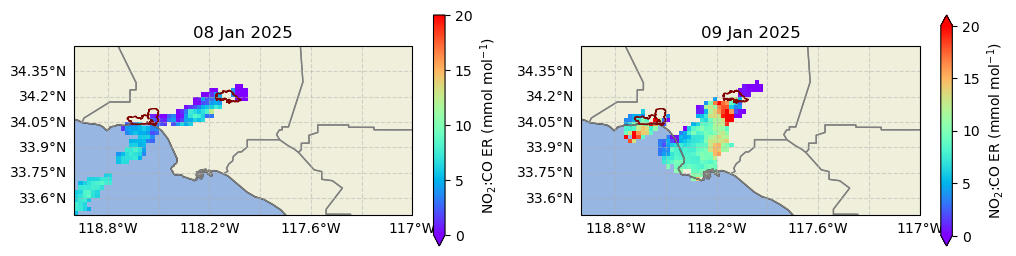

In [13]:
dates = pd.date_range('2025-01-08', '2025-01-09')

n = dates.size
_, axs = plt.subplots(1, n, figsize=(6*n, 3), subplot_kw={'projection': ccrs.PlateCarree()})

for ax, date in zip(axs, dates):
    nbplt.plot_gridded_enhancement(
        'static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
        date=date,
        variable='Time/enhancement_ratio',
        extent=nbcst.LA_EXTENT,
        vmin=0, vmax=20, cmap='rainbow',
        plume_mask=la_plume_mask,
        cblabel='NO$_2$:CO ER (mmol mol$^{{-1}}$)',
        feature_kws={'land': True, 'ocean': True}, ax=ax
    )
    ax.set_title(date.strftime('%d %b %Y'))
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'palisades', edgecolor='maroon', facecolor='none'
    )
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'eaton', edgecolor='maroon', facecolor='none'
    )
plt.savefig('figures/tropomi-std-ers.pdf', bbox_inches='tight')

## Custom retrieval plumes

In [14]:
def plot_mean_ers_for_dates(enh_file, dates, x_offset=pd.Timedelta(0), plume_mask=None, extent=None, ax=None, er_axis='y', **plot_kws):
    mean_ers = np.full(dates.size, np.nan)
    sigma_ers = np.full(dates.size, np.nan)
    for idate, date in enumerate(dates):
        er_dict = nber.load_enhancements_for_date(
            grid_file=enh_file, date=date, variable='Time/enhancement_ratio',
            plume_mask=plume_mask, extent=extent
        )
        ers = er_dict['values']
        mean_ers[idate] = np.nanmean(ers)
        sigma_ers[idate] = np.nanstd(ers, ddof=1)

    ax = ax or plt.gca()
    plot_kws.setdefault('ls', 'none')
    plot_kws.setdefault('marker', 'o')

    if er_axis == 'y':
        date_axis = ax.xaxis
        set_er_label = ax.set_ylabel
        ax.errorbar(dates + x_offset, mean_ers, yerr=sigma_ers, **plot_kws)
    elif er_axis == 'x':
        date_axis = ax.yaxis
        set_er_label = ax.set_xlabel
        ax.errorbar(mean_ers, dates + x_offset, xerr=sigma_ers, **plot_kws)
    else:
        raise ValueError('er_axis must be "x" or "y"')
        
    
    set_er_label('NO$_2$:CO mean enhancement ratio (mmol mol$^{-1}$)')
    plt.setp(date_axis.get_majorticklabels(), rotation=90)
    date_axis.set_major_locator(mdates.DayLocator(interval=1))
    date_axis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.grid(True, axis=er_axis)

In [15]:
def custom_priors_example(date=pd.Timestamp(2025,1,9), tgt_lon=-118.0, tgt_lat=34.2, tgt_time=pd.Timestamp(2025,1,9,18,10)):
    interp = make_custom_l2.ComboLatLonPresInterp.for_date(date)
    # _, axs = plt.subplots(1, 3, figsize=(18,4), sharey=True)
    new_pres = np.linspace(1, 1e5, 10)

    _, ax, ax2 = jplt.create_twin_axes_with_color(color2='gray', twin='y')
    handles = []
    handles.extend(
        ax.plot(
            1e6*interp.tropess_interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
            marker='o', color='tab:red', label='TROPESS CO (ppm)'
        )
    )

    handles.extend(
        ax.plot(
            1e9*interp.tropomi_interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
            marker='^', color='tab:blue', label='TROPOMI NO$_2$ prior (ppb)'
        )
    )
    ax.set_xlabel('VMR (ppm or ppb)')
    ax.set_ylabel('Pressure (hPa)')
    
    handles.extend(
        ax2.plot(
            interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
            marker='x', color='black', label='Combined (unitless)'
        )
    )
    ax2.set_xlabel('Combined shape')
    ax2.set_ylabel('Pressure (Pa)')
    ax.invert_yaxis()
    ax.grid(axis='y')
    ax.legend(handles=handles)

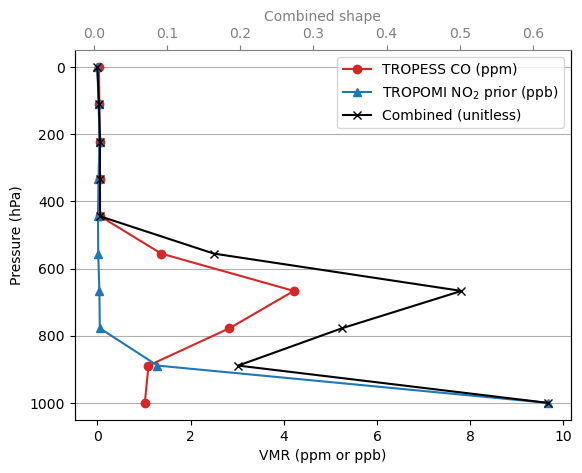

In [16]:
custom_priors_example()
plt.savefig('figures/custom-priors-example.pdf', bbox_inches='tight')

In [55]:
def plot_tropess_profile_ensemble(
    species: str,
    date: pd.Timestamp,
    extents: list[float],
    step=0,
    vscale: float = 1.0,
    units: str = 'mol/mol',
    good_only: bool = False,
    day_only: bool = True,
    cbcolumn: str = 'total',
    cmap='viridis',
    vmin=None,
    vmax=None,
    ax = None
):
    data = nbtrdat.load_muses_cols(muses_root_dir='static-data/tropess/', species=species, date=date, step=step)
    ii = nbtrdat.make_filter_index(data, extents=extents, good_only=good_only, day_only=day_only)
    xvals = data['x'][ii]
    xvals[xvals < -990] = np.nan
    xvals *= vscale
    pvals = data['p'][ii]
    pvals[pvals < -990] = np.nan

    icol = nbtrdat.TROPESS_COL_INDS[cbcolumn]
    cvals = data['columns'][ii, icol] * vscale / data['air_columns'][ii, icol]

    if vmin is None:
        vmin = np.nanmin(cvals)
    if vmax is None:
        vmax = np.nanmax(cvals)

    cmapper = jplt.ColorMapper(vmin, vmax, cmap=cmap)
    ax = ax or plt.gca()
    for x, p, c in zip(xvals, pvals, cvals):
        ax.plot(x, p, color=cmapper(c), lw=0.5)
    plt.colorbar(cmapper, ax=ax, label=f'{species.upper()} {cbcolumn} column avg. ({units})')
    if not ax.yaxis_inverted():
        ax.invert_yaxis()
    ax.grid(True)
    ax.set_ylabel('Pressure (hPa)')
    ax.set_xlabel(f'{species.upper()} ({units})')

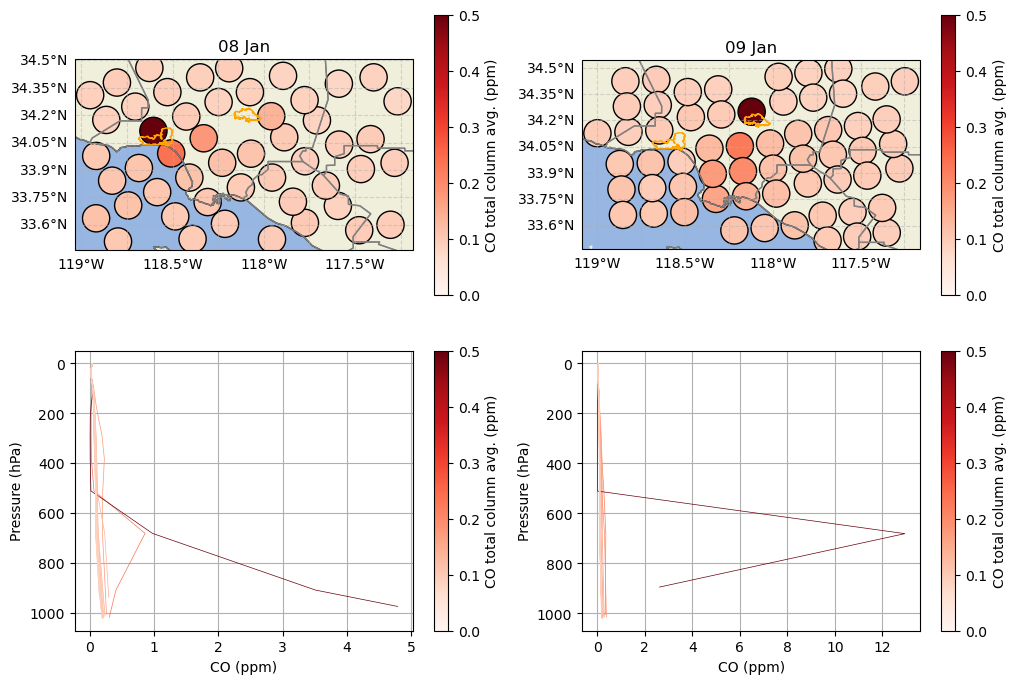

In [78]:
co_scatter_kws = dict(
    column='total',
    col_avg=True,
    vscale=1e6,
    vmin=0, vmax=0.5,
    cmap='Reds',
    cblabel='CO total column avg. (ppm)'
)

fig = plt.figure(figsize=(12,8))
gs = GridSpec(2, 2)
dates = pd.date_range('2025-01-08', '2025-01-09')

for idate, date in enumerate(dates):
    ax_map = fig.add_subplot(gs[0, idate], projection=ccrs.PlateCarree())
    nbplt.plot_muses_columns(
        muses_root='static-data/tropess/',
        species='CO', date=date, extents=nbcst.LA_EXTENT, ax=ax_map, **co_scatter_kws
    )
    ax_map.set_title(f'{date:%d %b}')
    nbpu.add_fire_perimeter(
        ax_map, 'static-data/fire-progression/fire-perimeters.geojson',
        'palisades', edgecolor='orange', facecolor='none'
    )
    nbpu.add_fire_perimeter(
        ax_map, 'static-data/fire-progression/fire-perimeters.geojson',
        'eaton', edgecolor='orange', facecolor='none'
    )

    ax_prof = fig.add_subplot(gs[1, idate])
    plot_tropess_profile_ensemble(
        'CO', date, nbcst.LA_EXTENT, cmap='Reds',
        vscale=1e6, vmin=co_scatter_kws['vmin'], vmax=co_scatter_kws['vmax'],
        units='ppm', ax=ax_prof
    )
plt.savefig('figures/tropess-co-profiles.pdf', bbox_inches='tight')

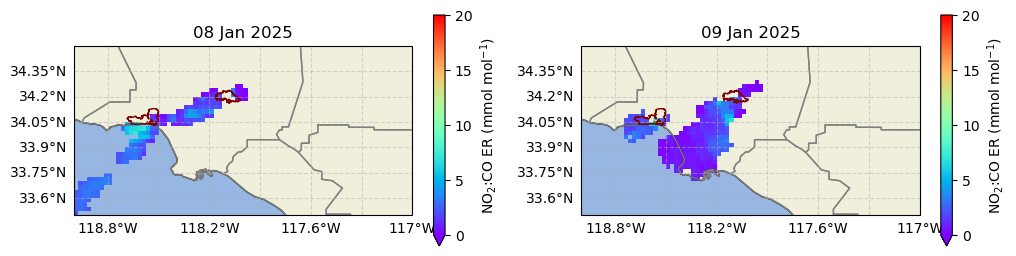

In [17]:
dates = pd.date_range('2025-01-08', '2025-01-09')

n = dates.size
_, axs = plt.subplots(1, n, figsize=(6*n, 3), subplot_kw={'projection': ccrs.PlateCarree()})

for ax, date in zip(axs, dates):
    nbplt.plot_gridded_enhancement(
        'static-data/tropomi-custom/enhancements/enhancement_eaton_and_palisades.nc',
        date=date,
        variable='Time/enhancement_ratio',
        extent=nbcst.LA_EXTENT,
        vmin=0, vmax=20, cmap='rainbow',
        plume_mask=la_custom_plume_mask,
        cblabel='NO$_2$:CO ER (mmol mol$^{{-1}}$)',
        feature_kws={'land': True, 'ocean': True}, ax=ax
    )
    ax.set_title(date.strftime('%d %b %Y'))
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'palisades', edgecolor='maroon', facecolor='none'
    )
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'eaton', edgecolor='maroon', facecolor='none'
    )
plt.savefig('figures/tropomi-custom-ers.pdf', bbox_inches='tight')

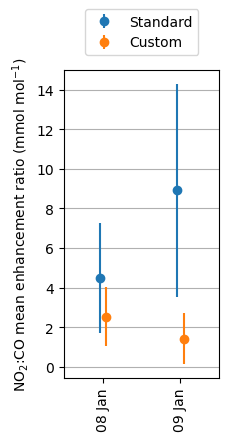

In [18]:
dates = pd.date_range('2025-01-08', '2025-01-09')

_, ax = plt.subplots(figsize=(2,4))

plot_mean_ers_for_dates(
    'static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
    dates,
    x_offset=pd.Timedelta(minutes=-60),
    plume_mask=la_custom_plume_mask,
    extent=nbcst.LA_EXTENT,
    label='Standard',
    ax=ax
)

plot_mean_ers_for_dates(
    'static-data/tropomi-custom/enhancements/enhancement_eaton_and_palisades.nc',
    dates,
    x_offset=pd.Timedelta(minutes=60),
    plume_mask=la_custom_plume_mask,
    extent=nbcst.LA_EXTENT,
    label='Custom',
    ax=ax
)

ax.set_xlim(pd.Timestamp(2025,1,7,12), pd.Timestamp(2025,1,9,12))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.025))
plt.savefig('figures/tropomi-std-vs-custom-ers.pdf', bbox_inches='tight')

## NH3 plumes

In [38]:
def make_standard_nh3_plot(axs=None, vmax=7.5):
    if axs is None:
        _, axs = plt.subplots(1, 2, figsize=(12,3), subplot_kw={'projection': ccrs.PlateCarree()})

    for ax, day in zip(axs, [8,9]):
            _plot_one_nh3(
                tropess_file=f'static-data/tropess/custom-nh3/summary/NH3/2025-01-{day:02d}_TROPESS_CrIS-SNPP_L2_Summary_NH3_20260212_MUSES_R1p17_SC_BOX_F0p1_J0-1.nc',
                use_plume_ratio=False,
                vscale=1e9, extents=nbcst.LA_EXTENT, cblabel='XNH$_3$ (ppb)',
                cmap='Reds', vmin=0.0, vmax=vmax, ax=ax
            )
            ax.set_title(f'Jan {day}, standard')

    jplt.label_subplots(axs.flatten(), xpos=-0.025, ypos=1.025,)


def make_custom_nh3_plot(axs=None, vmax=7.5):
    if axs is None:
        _, axs = plt.subplots(1, 2, figsize=(12,3), subplot_kw={'projection': ccrs.PlateCarree()})

    for ax, day in zip(axs, [8,9]):
            _plot_one_nh3(
                tropess_file=f'static-data/tropess/custom-nh3/summary/NH3/2025-01-{day:02d}_TROPESS_CrIS-SNPP_L2_Summary_NH3_20260212_MUSES_R1p17_SC_BOX_F0p1_J0-1.nc',
                use_plume_ratio=True,
                vscale=1e9, extents=nbcst.LA_EXTENT, cblabel='XNH$_3$ (ppb)',
                cmap='Reds', vmin=0.0, vmax=vmax, ax=ax
            )
            ax.set_title(f'Jan {day}, custom')

    jplt.label_subplots(axs.flatten(), xpos=-0.025, ypos=1.025,)


def make_combined_nh3_plot(std_vmax=7.5, custom_vmax=7.5):
    _, axs = plt.subplots(2, 2, figsize=(12,6), subplot_kw={'projection': ccrs.PlateCarree()})
    make_standard_nh3_plot(axs=axs[0], vmax=std_vmax)
    make_custom_nh3_plot(axs=axs[1], vmax=custom_vmax)
    

def _plot_one_nh3(tropess_file, use_plume_ratio=False, vscale=1.0, extents=None, cblabel='', day_only=True, ax=None, **scatter_kws):
    data = _load_tropess_nh3(tropess_file, day_only, use_plume_ratio)
    if ax is None:
        _, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})

    scatter_kws.setdefault('s', 384)
    scatter_kws.setdefault('edgecolor', 'k')
    h = ax.scatter(data['lon'], data['lat'], c=data['xcol'] * vscale, **scatter_kws)
    plt.colorbar(h, ax=ax, label=cblabel)
    nbplt.add_features(ax, land=True, ocean=True)
    if extents is not None:
        ax.set_extent(extents)
        

def _load_tropess_nh3(tropess_file, day_only: bool, use_plume_ratio: bool):
    with Dataset(tropess_file) as ds:
        data = {
            'lon': ds['longitude'][:],
            'lat': ds['latitude'][:],
            'xcol': ds['col'][:] / ds['col_dry_air'][:]
        }

        if use_plume_ratio:
            # This is a fill when CO is too small to reliably determine the plume vertical shape
            print('Scaling by ratio_plume')
            ratio = ds['ratio_plume'][:].filled(1.0)
            data['xcol'] *= ratio

        if day_only:
            xx = ds['geophysical/day_night_flag'][:] == 1
            data = {k: v[xx] for k, v in data.items()}

        return data

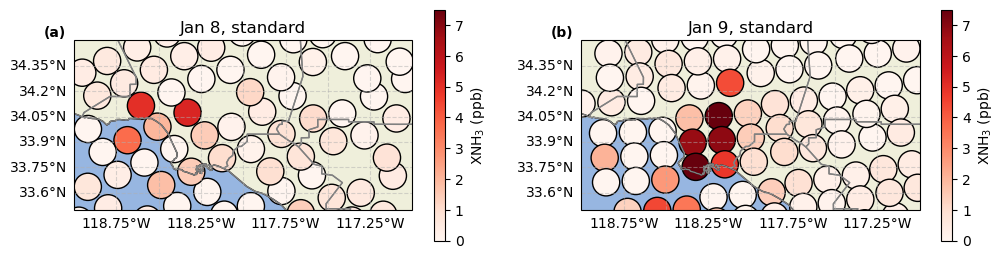

In [42]:
make_standard_nh3_plot()
plt.savefig('figures/tropess-std-nh3.pdf', bbox_inches='tight')

Scaling by ratio_plume
Scaling by ratio_plume


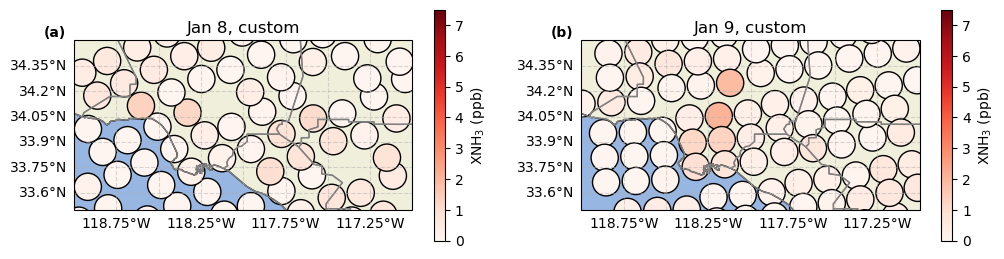

In [43]:
make_custom_nh3_plot()
plt.savefig('figures/tropess-custom-nh3.pdf', bbox_inches='tight')

## Fire progression

First, reproduce the VIIRS JPSS-2 multi-panel figure from the Nov workshop. Then work on a figure that shows a timeseries of FRP/fire counts from GOES, MODIS, and VIIRS in Altadena and outside. Will need to figure out how to make the box based on destroyed structures.

In [21]:
def make_frp_altadena_timeseries_with_maps(
    goes_frp: nberf.FrpProvider, modis_terra_frp: nberf.FrpProvider, viirs_jpss2_frp: nberf.FrpProvider,
    structure_dmg: gpd.GeoDataFrame, perimeter: gpd.GeoDataFrame,
    map_min_time='2025-01-07 12:00', map_max_time='2025-01-10 00:00',
    timeseries_min='2025-01-07', timeseries_max='2025-01-10',
):
    modis_df = modis_terra_frp.detection_df()
    viirs_df = viirs_jpss2_frp.detection_df()

    modis_df = modis_df[(modis_df.datetime > map_min_time) & (modis_df.datetime < map_max_time)]
    viirs_df = viirs_df[(viirs_df.datetime > map_min_time) & (viirs_df.datetime < map_max_time)]

    polys = _altadena_structure_perimeter(structure_dmg)
    altadena_rect = Polygon(miscutils.polygon_to_rect(polys[0]))

    fig_and_ax = _setup_frp_altadena_axes(modis_df, viirs_df)
    ax = fig_and_ax['timeseries']
    _, _, ax2 = jplt.create_twin_axes_with_color(color2='gray', ax=ax)
    handles = []
    handles.extend(
        nbplt.plot_frp_timeseries(goes_frp, min_time=timeseries_min, max_time=timeseries_max, bounds=altadena_rect,
                                  color='black', marker='o', label='Altadena', ax=ax)
    )
    handles.extend(
        nbplt.plot_frp_timeseries(goes_frp, min_time=timeseries_min, max_time=timeseries_max,
                                  bounds=nbutils.extents_to_polygon(nbcst.EATON_EXTENT), color='gray',
                                  marker='.', label='Full Eaton fire', ax=ax2)
    )
    ax.legend(handles=handles, ncols=2)
    ax.grid(axis='y')
    ax2.grid(False)
    ax.xaxis.set_major_locator(mdates.HourLocator([0,6,12,18]))

    _add_frp_maps(
        fire_df=viirs_df,
        structure_df=structure_dmg,
        perimeter_df=perimeter,
        axs=fig_and_ax['viirs'],
        colors=fig_and_ax['viirs_colors'],
        timeseries_ax=ax,
        fig=fig_and_ax['fig'],
        sat='VIIRS (JPSS-2)',
        label_lons=False
    )

    struct_h = _add_frp_maps(
        fire_df=modis_df,
        structure_df=structure_dmg,
        perimeter_df=perimeter,
        axs=fig_and_ax['modis'],
        colors=fig_and_ax['modis_colors'],
        timeseries_ax=ax,
        fig=fig_and_ax['fig'],
        sat='MODIS (Terra)',
        label_lons=True,
    )
    plt.colorbar(struct_h, cax=fig_and_ax['cb'], label='# structures destroyed')


def _altadena_structure_perimeter(structure_dmg: gpd.GeoDataFrame,):
    h, x, y = nbstruct.make_structure_damage_2d_hist(structure_dmg, extent=nbcst.ALTADENA_EXTENT)
    m = miscutils.flood_fill_at_coords(h, x, y, -118.15, 34.195, 20)
    return miscutils.extract_polygon_from_mask(m, x, y)
    

def _setup_frp_altadena_axes(modis_df, viirs_df):
    n = modis_df.overpass_index.unique().size
    if n != viirs_df.overpass_index.unique().size:
        raise NotImplementedError('Different numbers of MODIS and VIIRS overpasses')

    colors = plt.get_cmap('tab10')
    modis_colors = [colors(i) for i in range(n)]
    viirs_colors = [colors(i) for i in range(n, 2*n)]
    
    fig = plt.figure(figsize=(12,6))
    wr = [10] * n + [1]
    gs = GridSpec(nrows=3, ncols=n+1, height_ratios=[1,1,3], hspace=0.4, width_ratios=wr)
    modis_axs = [fig.add_subplot(gs[0,i], projection=ccrs.PlateCarree()) for i in range(n)]
    for i, ax in enumerate(modis_axs):
        for spine in ax.spines.values():
            spine.set_color(modis_colors[i])
    viirs_axs = [fig.add_subplot(gs[1,i], projection=ccrs.PlateCarree()) for i in range(n)]
    for i, ax in enumerate(viirs_axs):
        for spine in ax.spines.values():
            spine.set_color(viirs_colors[i])
    timeseries_ax = fig.add_subplot(gs[2,:])
    cb_ax = fig.add_subplot(gs[:2, -1])
    return {
        'fig': fig,
        'modis': modis_axs,
        'modis_colors': modis_colors,
        'viirs': viirs_axs,
        'viirs_colors': viirs_colors,
        'timeseries': timeseries_ax,
        'cb': cb_ax
    }


def _add_frp_maps(fire_df, structure_df, perimeter_df, axs, timeseries_ax, fig, colors, sat, label_lons):
    n = fire_df.overpass_index.unique().size
    x = np.linspace(0, 1, num=n+1)[:n]
    width = 1 / n * 0.96
    
    for i, (_, overpass_df) in enumerate(fire_df.groupby('overpass_index')):
        ax = axs[i]
        struct_h = nbstruct.plot_structures_hist(structure_df, extent=nbcst.ALTADENA_EXTENT, add_colorbar=False, ax=ax)
        nbstruct.plot_final_perimeter(perimeter_df, 'eaton', ax=ax)
        ax.plot(overpass_df.longitude, overpass_df.latitude, color='red', ls='none', marker='.', markersize=2)
        
        ax.set_extent(nbcst.EATON_EXTENT)
        start = overpass_df.datetime.min().tz_convert('-08:00').tz_localize(None)
        ax.set_title(f'{sat}\n{start:%d %b %H:%M} PST', fontsize=8, color=colors[i])
        gl = ax.gridlines(draw_labels=True)
        gl.right_labels = False
        gl.bottom_labels = False
        if i > 0:
            gl.left_labels = False
        if not label_lons:
            gl.top_labels = False

        timeseries_ax.axvline(start, ls='--', color=colors[i])

        patch = ConnectionPatch(
            xyA=[start.tz_localize(None), timeseries_ax.get_ylim()[1]],
            xyB=[0.5, 0],
            coordsA='data',
            coordsB=ax.transAxes,
            axesA=timeseries_ax,
            axesB=ax,
            color=colors[i],
            zorder=0
        )
        fig.add_artist(patch)
    return struct_h

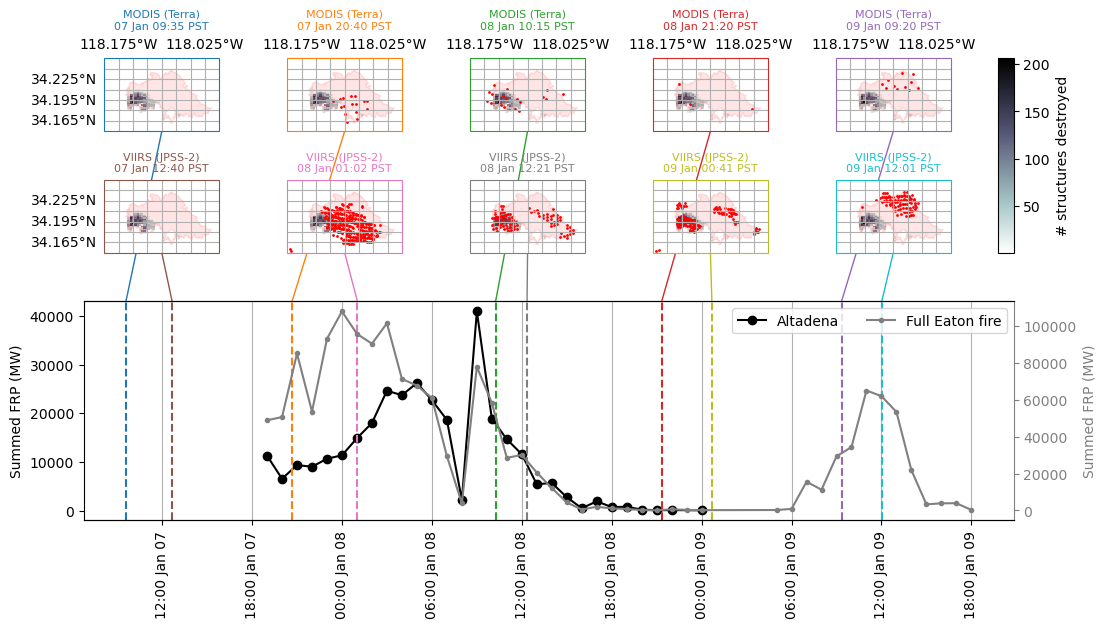

In [22]:
make_frp_altadena_timeseries_with_maps(goes_frp, modis_terra_frp, viirs_jpss2_frp, structure_damage_gdf, perimeters_gdf)
plt.savefig('figures/eaton-fire-progression.pdf', bbox_inches='tight')

## Topography and fire progression

In [23]:
def make_topography_fire_progression_plot(
    structure_gdf: gpd.GeoDataFrame,
    perimeters_gdf: gpd.GeoDataFrame,
    viirs_frp: nberf.FrpProvider,
    ax=None
):
    if ax is None:
        _, ax = plt.subplots(figsize=(6,3), subplot_kw={'projection': ccrs.PlateCarree()})


     
    plot_nasadem_topo(extent=nbcst.EATON_EXTENT, cmap='Greys', ax=ax)
    hstruct = nbstruct.plot_altadena_structure_perimeter(structure_gdf, ax=ax, facecolor='none', edgecolor='blue', ls='-.', alpha=1, zorder=9)
    hfire = nbstruct.plot_final_perimeter(perimeters_gdf, name='eaton', ax=ax, facecolor='none', ls='--', alpha=1, zorder=10)
    hfrp = plot_frps_colored_by_overpass(
        viirs_frp.detection_df(),
        pd.Timestamp(2025,1,8, tz='-08:00'),
        pd.Timestamp(2025,1,9,18, tz='-08:00'),
        extent=nbcst.EATON_EXTENT, ax=ax
    )

    handles = [hstruct, hfire] + hfrp
    ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.025), ncols=2)

def plot_nasadem_topo(ax=None, add_cb=True, extent=None, dem_file='static-data/topography/socal_nasadem.tif', **pcolor_kws):
    if ax is None:
        _, ax = plt.subplots(figsize=(6,3), subplot_kw={'projection': ccrs.PlateCarree()})

    with rasterio.open(dem_file) as tiff:
        data = np.ma.masked_equal(tiff.read(), tiff.nodata)[0]
        data_crs = ccrs.Projection(tiff.crs)

        cols = np.arange(tiff.width)
        rows = np.arange(tiff.height)
        x_coords, _ = tiff.transform * (cols + 0.5, np.zeros_like(cols))
        _, y_coords = tiff.transform * (np.zeros_like(rows), rows + 0.5)

    
    if extent is not None:
        x1, x2, y1, y2 = extent
        xx = (x_coords >= x1) & (x_coords <= x2)
        yy = (y_coords >= y1) & (y_coords <= y2)
        x_coords = x_coords[xx]
        y_coords = y_coords[yy]
        data = data[yy][:, xx]

    pcolor_kws.setdefault('cmap', 'Greens')
    pcolor_kws.setdefault('vmin', 0)
    h = ax.pcolormesh(x_coords, y_coords, data, transform=data_crs, **pcolor_kws)
    plt.colorbar(h, ax=ax, label='Elevation (m)')
    gl = ax.gridlines(draw_labels=True)
    gl.right_labels = False
    gl.top_labels = False

def plot_frps_colored_by_overpass(frp_df, min_time, max_time, cmap='Set2', extent=None, ax=None):
    tt = (frp_df.datetime >= min_time) & (frp_df.datetime <= max_time)
    frp_df = frp_df.loc[tt, :]
    colors = plt.get_cmap(cmap)
    markers = '.+^x'

    if ax is None:
        _, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})

    handles = []
    for i_overpass, (_, overpass_df) in enumerate(frp_df.groupby('overpass_index')):
        color = colors(i_overpass)
        start = overpass_df.datetime.min().tz_convert('-08:00').tz_localize(None)
        label = f'VIIRS FRP, {start:%d %b %H:%M} PST'
        h = ax.plot(overpass_df.longitude, overpass_df.latitude, marker=markers[i_overpass], color=color,
                    ls='none', label=label)
        handles.extend(h)
    if extent is not None:
        ax.set_extent(extent)
    return handles

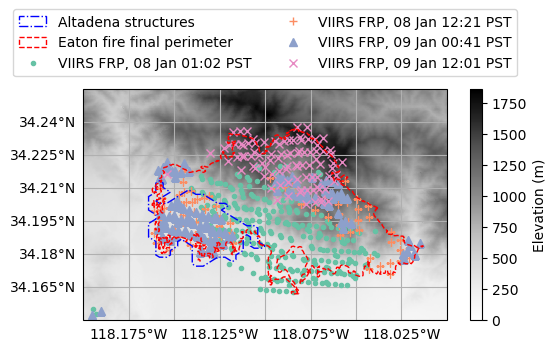

In [24]:
make_topography_fire_progression_plot(structure_damage_gdf, perimeters_gdf, viirs_jpss2_frp)
plt.savefig('figures/eaton-fire-topography.pdf', bbox_inches='tight')

## Aerosol properties

In [25]:
def make_no2_er_vs_aerosol_plots(plume_mask, dates=pd.date_range('2025-01-08', '2025-01-09')):

    aer_kws = {'scene': 'eaton_and_palisades', 'plume_mask': plume_mask, 'extent': nbcst.LA_EXTENT}
    aer_values = {
        'AOD (unitless)': partial(nbaer.load_aerosol_variable_for_date, quantity='aer', variable='aod', **aer_kws),
        'SSA (unitless)': partial(nbaer.load_aerosol_variable_for_date, quantity='aer', variable='ssa', **aer_kws),
        'ALH (m)': partial(nbaer.load_variable_for_date, quantity='alh', variable='alh', **aer_kws),
    }

    gas_values = {
        'NO$_2$ trop. col. (mol m$^{-2}$)': partial(
            nbgrid.load_variable_for_date,
            quantity='no2',
            scene='eaton_and_palisades',
            variable='no2_trop',
            plume_mask=plume_mask,
            extent=nbcst.LA_EXTENT,
        ),

        'NO$_2$:CO ER (mmol mol$^{-1}$)': partial(
            nber.load_enhancements_for_date,
            grid_file='static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
            variable='Time/enhancement_ratio',
            plume_mask=plume_mask,
            extent=nbcst.LA_EXTENT,
        )
    }

    with plt.rc_context({'axes.formatter.limits': (-2,3), 'axes.formatter.use_mathtext': True}):
        nx = len(aer_values)
        ny = len(gas_values)
        _, axs = plt.subplots(ny, nx, figsize=(nx*4, ny*4), sharex='col', sharey='row')
    
        colors = plt.get_cmap('tab10')
        
        for ax_row, (gas_label, gas_fxn) in zip(axs, gas_values.items()):
            for ax, (aer_label, aer_fxn) in zip(ax_row, aer_values.items()):
                for idate, date in enumerate(dates):
                    aer_data = aer_fxn(date=date)
                    gas_data = gas_fxn(date=date)
                    assert np.allclose(aer_data['lon'], gas_data['lon']), 'lon grids do not match'
                    assert np.allclose(aer_data['lat'], gas_data['lat']), 'lat grids do not match'
    
                    ii = np.isfinite(aer_data['values'].filled(np.nan)) & np.isfinite(gas_data['values'].filled(np.nan))
                    ax.plot(aer_data['values'][ii], gas_data['values'][ii], ls='none', marker='.', color=colors(idate), label=date.strftime('%d %b'))
                ax.set_xlabel(aer_label)
                ax.set_ylabel(gas_label)
                ax.grid(True)
    
        axs[0, nx // 2].legend(ncols=2, loc='lower center', bbox_to_anchor=(0.5, 1.025))
        for ax in axs[:, 1:].flat:
            ax.set_ylabel('')
        for ax in axs[:-1].flat:
            ax.set_xlabel('')
        jplt.label_subplots(axs.flatten(), xpos=0.1, ypos=0.94)

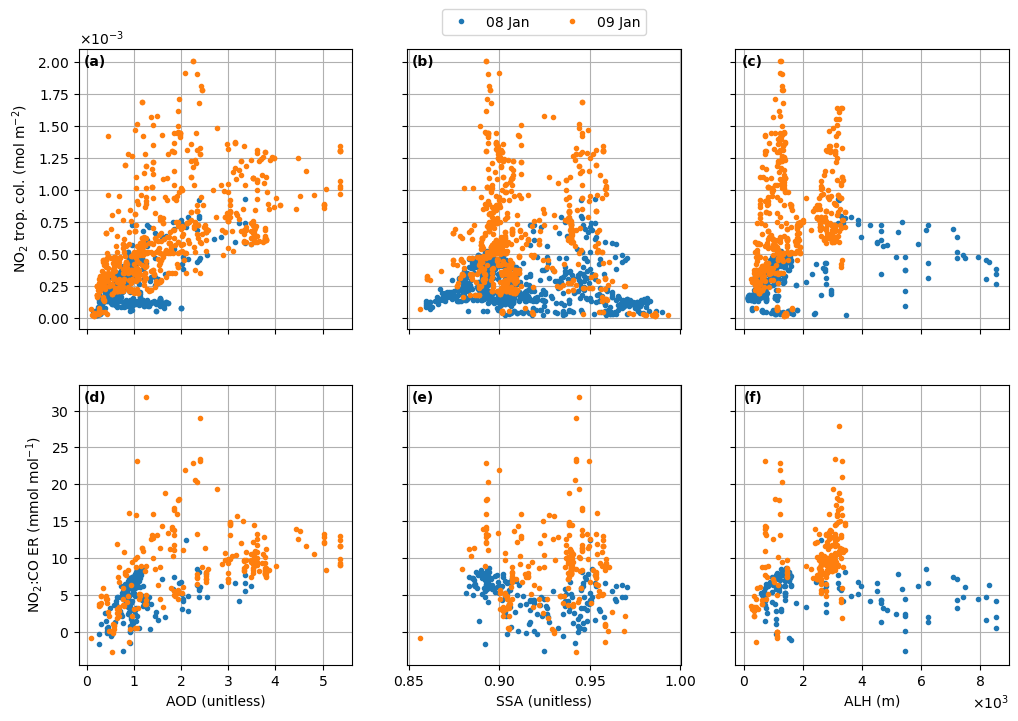

In [26]:
make_no2_er_vs_aerosol_plots(la_plume_mask)
plt.savefig('figures/tropomi-aerosol-properties.pdf', bbox_inches='tight')

## NO:NO$_2$ ratio

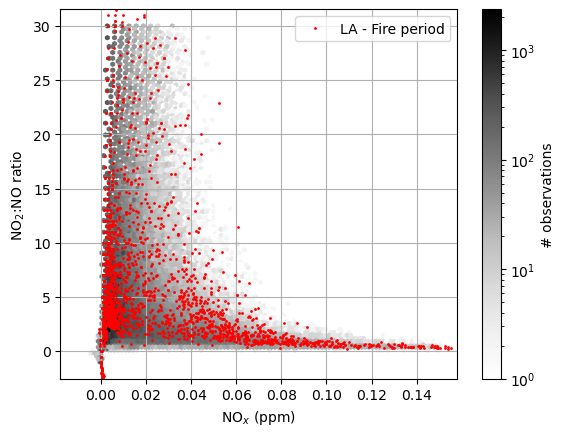

In [27]:
ax = plt.gca()
nbcarb.plot_carb_ratio_vs_nox(carb_nox, extent=[-0.01, 0.15, -1, 30], ax=ax)
ax.set_xlim(ax.get_xlim())
ax.set_ylim(ax.get_ylim())
nbcarb.plot_carb_ratio_vs_nox_subset(
    carb_nox,
    time_extent=[pd.Timestamp(2025,1,7,tz='-08:00'), pd.Timestamp(2025,1,11,tz='-08:00')],
    spatial_extent=[-120, -115, 33, 35],
    markersize=2, label='LA - Fire period',
    ax=ax
)
ax.legend(loc='upper right')
plt.savefig('figures/carb-no2-to-no.pdf', bbox_inches='tight')

## Ozone titration plots

In [28]:
def make_o3_titration_plot(perimeter_df: gpd.GeoDataFrame):
    o3_scatter_kws = dict(
        column='trop',
        col_avg=True,
        vscale=1e9,
        vmin=40, vmax=80,
        cmap='PuRd',
        cblabel='Trop. XO$_3$ (ppb)',
        s=64,
    )

    dates = pd.date_range('2025-01-07', '2025-01-09')
    nx = len(dates)
    fig = plt.figure(figsize=(12,4))
    gs = GridSpec(nrows=2, ncols=nx+1, width_ratios=[2]*nx + [1], height_ratios=[10,1], wspace=0.4)
    
    
    box_lon, box_lat = nbutils.default_upwind_box()
    box_poly = nbutils.default_upwind_box(as_poly=True)
    box_mean_xo3 = np.full(dates.shape, np.nan)
    box_sigma_xo3 = np.full(dates.shape, np.nan)

    cax = fig.add_subplot(gs[1, :nx])

    all_axs = []
    
    for idate, date in enumerate(dates):
        ax = fig.add_subplot(gs[idate], projection=ccrs.PlateCarree())
        all_axs.append(ax)
        nbplt.plot_muses_columns(
            'static-data/tropess/',
            'O3',
            date,
            extents=[-120, -116, 32, 36],
            ax=ax, cax=cax, no_colorbar=idate > 0, cbkw={'orientation': 'horizontal'},
            **o3_scatter_kws
        )
        nbpu.plot_box(box_lon, box_lat, ax=ax, color='green')
        nbstruct.plot_final_perimeter(perimeter_df, 'eaton', ax=ax, facecolor='none', edgecolor='darkred', alpha=1)
        ax.set_title(f'{date:%d %b}')

        box_mean_xo3[idate], box_sigma_xo3[idate] = _compute_mean_col_in_box(
            box_poly=box_poly, species='O3', date=date, column=o3_scatter_kws['column'], col_avg=o3_scatter_kws['col_avg']
        )

    ax = fig.add_subplot(gs[0, -1])
    all_axs.append(ax)
    ax.errorbar(dates, box_mean_xo3 * o3_scatter_kws['vscale'], yerr=box_sigma_xo3 * o3_scatter_kws['vscale'],
                ls='none', marker='o', color='green')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)
    ax.grid(axis='y')
    ax.set_xlim(dates[0] - pd.Timedelta(hours=12), dates[-1] + pd.Timedelta(hours=12))
    ax.set_ylabel('Tropospheric XO$_3$ (ppb)')
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    
    jplt.label_subplots(all_axs, xpos=0.975, ypos=0.94)


def _compute_mean_col_in_box(box_poly, species, date, column, col_avg, debug_plot=False):
    data = nbtrdat.load_muses_cols('static-data/tropess/', species, date)
    lon = data['lon']
    lat = data['lat']
    cols = nbtrdat.get_muses_col_values(data, column, col_avg)

    ii = nbtrdat.make_filter_index(data, extents=[-180, 180, -90, 90], good_only=False, day_only=True)
    lon = lon[ii]
    lat = lat[ii]
    cols = cols[ii]
    
    is_in = nbutils.in_poly(lon, lat, box_poly)
    mean_col = np.nanmean(cols[is_in])
    sigma_col = np.nanstd(cols[is_in])

    if debug_plot:
        _, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
        h = ax.scatter(lon[is_in], lat[is_in], c=cols[is_in])
        plt.colorbar(h, ax=ax)
        plot_box(*box_poly.exterior.xy, color='k')
        add_features(ax)
        return mean_col, sigma_col, ax
    else:
        return mean_col, sigma_col

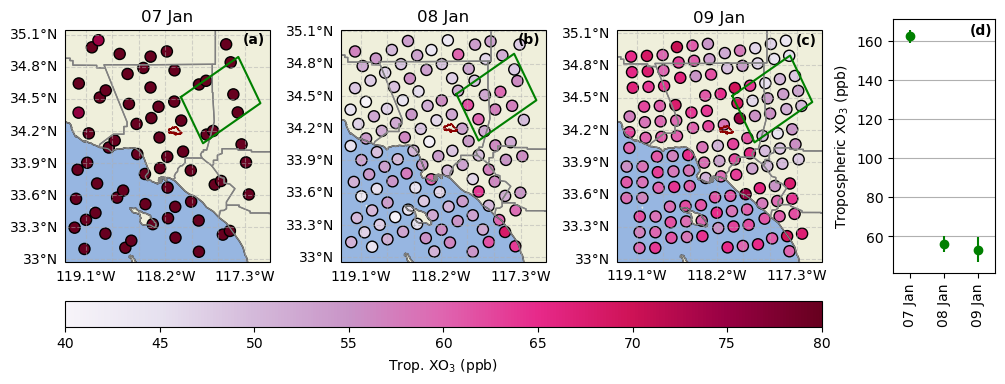

In [29]:
make_o3_titration_plot(perimeters_gdf)
plt.savefig('figures/tropess-o3', bbox_inches='tight')

## FRP diurnal cycle

In [30]:
def make_frp_by_hour_plot():
    anderson_fires_by_hour = nbplt.make_goes_frp_by_hour_df(goes_west_coast_frp, anderson_cfg['scene'])
    la_fires_by_hour = nbplt.make_goes_frp_by_hour_df(goes_west_coast_frp, la_cfg['scene'])
    
    _, axs = plt.subplots(1, 2, figsize=(12,4))
    ax = axs[0]
    nbplt.frp_by_hour_violins(anderson_fires_by_hour, ax=ax)
    nbplt.frp_by_hour_per_date(la_fires_by_hour, ax=ax)
    ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.025))
    ax.set_ylabel('Mean FRP (MW)')
    
    ax = axs[1]
    nbplt.frp_by_hour_violins(anderson_fires_by_hour, column='total_frp', ax=ax)
    nbplt.frp_by_hour_per_date(la_fires_by_hour, column='total_frp', ax=ax)
    ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.025))
    ax.set_ylabel('Summed FRP (MW)')
    jplt.label_subplots(axs, xpos=0.075)

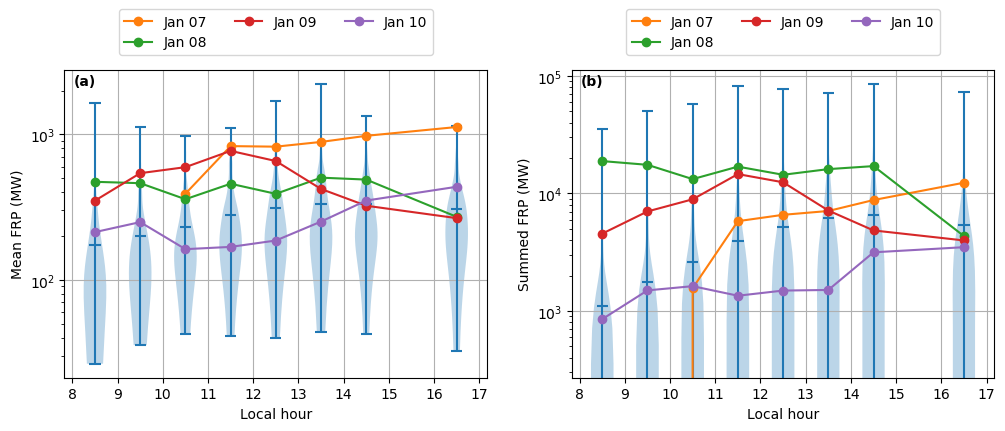

In [31]:
make_frp_by_hour_plot()
plt.savefig('figures/frp-diurnal-evolution', bbox_inches='tight')

## Comparison to previous fires

In [32]:
def make_er_vs_frp_plot(frp_col='mean_frp'):
    west_coast_dfs, la_dfs = _prep_frp_er_dfs()

    _, axs = plt.subplots(1, 3, figsize=(15,4), sharey=True)
    ax = axs[0]
    nbplt.fire_fit_plot(west_coast_dfs['VIIRS'], frp_col, ax=ax)
    _add_eaton_points(ax, la_dfs['VIIRS'], frp_col)
    _edit_er_vs_frp_xlabel(ax, 'VIIRS')
    # ax.text(0.98, 0.98, 'VIIRS', transform=ax.transAxes, ha='right', va='top')

    ax = axs[1]
    nbplt.fire_fit_plot(west_coast_dfs['GOES']['0900-1200'], frp_col, ax=ax)
    _add_eaton_points(ax, la_dfs['GOES']['0900-1200'], frp_col)
    _edit_er_vs_frp_xlabel(ax, 'GOES between 0900 & 1200')
    # ax.text(0.98, 0.98, 'GOES, 0900-1200', transform=ax.transAxes, ha='right', va='top')

    ax = axs[2]
    nbplt.fire_fit_plot(west_coast_dfs['GOES']['1200-1500'], frp_col, ax=ax)
    _add_eaton_points(ax, la_dfs['GOES']['1200-1500'], frp_col)
    _edit_er_vs_frp_xlabel(ax, 'GOES between 1200 & 1500')
    # ax.text(0.98, 0.98, 'GOES, 1200-1500', transform=ax.transAxes, ha='right', va='top')

    for ax in axs[1:]:
        ax.set_ylabel('')
    for ax in axs:
        ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0125))

    jplt.label_subplots(axs, xpos=0.075, ypos=0.96)


def _edit_er_vs_frp_xlabel(ax, desc):
    quantity, units = ax.get_xlabel().split('(')
    # the trailing parentheses is still on "units"
    ax.set_xlabel(f'{quantity.strip()} from {desc} ({units}')
    

def _add_eaton_points(ax, eaton_df_dict, frp_col):
    dates_colors = {
        '2025-01-08': 'tab:green',
        '2025-01-09': 'tab:purple'
    }
    markers = '^*Pv'
    for mkr, (case, eaton_df) in zip(markers, eaton_df_dict.items()):
        for date, color in dates_colors.items():
            date = pd.to_datetime(date)
            if case:
                label = f'LA, {date:%d %b} ({case})'
            else:
                label = f'LA, {date:%d %b}'
            ax.plot(eaton_df.loc[date, frp_col], eaton_df.loc[date, 'er'], marker=mkr, markersize=12,
                    ls='none', color=color, label=label)




def _prep_frp_er_dfs():
    west_coast_dfs = {'VIIRS': None, 'GOES': dict()}

    west_coast_dfs['VIIRS'] = nberf.match_frps_to_ers_many_files(
        frp=viirs_west_coast_frp,
        er=slope_er_provider,
        scenes=anderson_cfg['scene'],
        local_hour_limits=(9, 12)
    )
    
    west_coast_dfs['GOES']['0900-1200'] = nberf.match_frps_to_ers_many_files(
        frp=goes_west_coast_frp,
        er=slope_er_provider,
        scenes=anderson_cfg['scene'],
        local_hour_limits=(9, 12)
    )
    
    west_coast_dfs['GOES']['1200-1500'] = nberf.match_frps_to_ers_many_files(
        frp=goes_west_coast_frp,
        er=slope_er_provider,
        scenes=anderson_cfg['scene'],
        local_hour_limits=(12, 15)
    )

    la_slope_dfs = {'VIIRS': dict(), 'GOES': dict()}

    la_slope_dfs['VIIRS']['std. NO$_2$'] = nberf.match_frps_to_ers_many_files(
        viirs_jpss2_frp,
        la_slope_er,
        scenes=la_cfg['scene'],
        local_hour_limits=(9,15)
    )

    la_slope_dfs['GOES']['0900-1200'] = dict()
    la_slope_dfs['GOES']['1200-1500'] = dict()
    la_slope_dfs['GOES']['0900-1200']['std. NO$_2$'] = nberf.match_frps_to_ers_many_files(
        goes_west_coast_frp,
        la_slope_er,
        scenes=la_cfg['scene'],
        local_hour_limits=(9,12)
    )
    
    la_slope_dfs['GOES']['1200-1500']['std. NO$_2$'] = nberf.match_frps_to_ers_many_files(
        goes_west_coast_frp,
        la_slope_er,
        scenes=la_cfg['scene'],
        local_hour_limits=(12,15)
    )

    la_slope_dfs['VIIRS']['custom NO$_2$'] = nberf.match_frps_to_ers_many_files(
        viirs_jpss2_frp,
        la_slope_er_cust_no2,
        scenes=la_cfg['scene'],
        local_hour_limits=(9,15)
    )
    
    la_slope_dfs['GOES']['0900-1200']['custom NO$_2$'] = nberf.match_frps_to_ers_many_files(
        goes_west_coast_frp,
        la_slope_er_cust_no2,
        scenes=la_cfg['scene'],
        local_hour_limits=(9,12)
    )
    
    la_slope_dfs['GOES']['1200-1500']['custom NO$_2$'] = nberf.match_frps_to_ers_many_files(
        goes_west_coast_frp,
        la_slope_er_cust_no2,
        scenes=la_cfg['scene'],
        local_hour_limits=(12,15)
    )

    return west_coast_dfs, la_slope_dfs

Matching for scene 1 of 15: anderson_lionshead
Matching for scene 2 of 15: anderson_august_complex
Matching for scene 3 of 15: anderson_lnu_complex
Matching for scene 4 of 15: anderson_scu_complex
Matching for scene 5 of 15: anderson_sqf_complex
Matching for scene 6 of 15: anderson_creek
Matching for scene 7 of 15: anderson_bootleg
Matching for scene 8 of 15: anderson_beckwourth
Matching for scene 9 of 15: anderson_lick_creek
Matching for scene 10 of 15: anderson_mcfarland
Matching for scene 11 of 15: anderson_monument
Matching for scene 12 of 15: anderson_river_complex
Matching for scene 13 of 15: anderson_antelope
Matching for scene 14 of 15: anderson_schneider_springs
Matching for scene 15 of 15: anderson_caldor
Matching for scene 1 of 15: anderson_lionshead
Matching for scene 2 of 15: anderson_august_complex
Matching for scene 3 of 15: anderson_lnu_complex
Matching for scene 4 of 15: anderson_scu_complex
Matching for scene 5 of 15: anderson_sqf_complex
Matching for scene 6 of 15: a

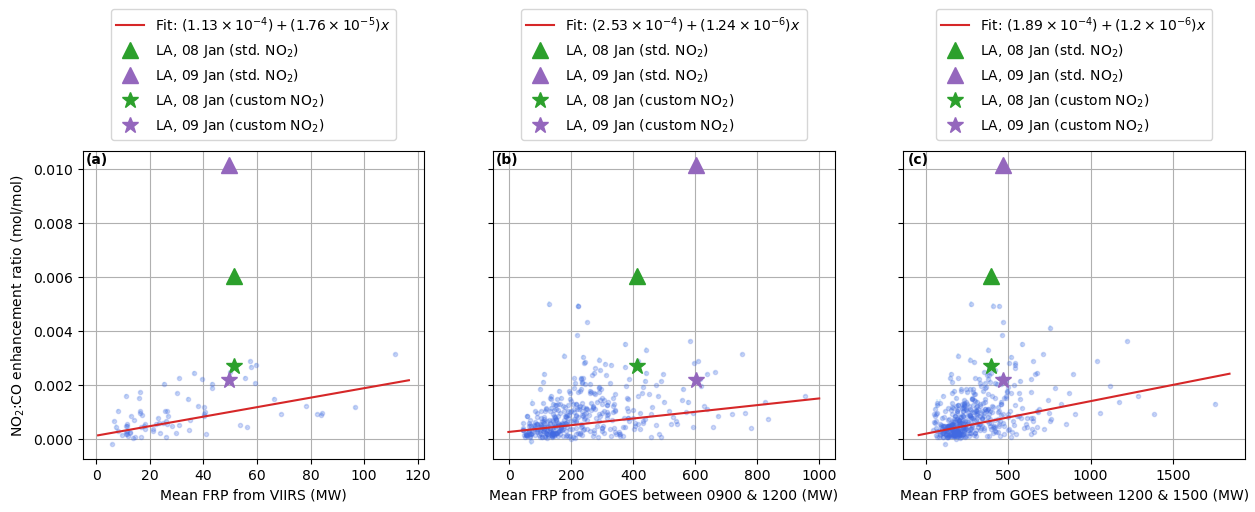

In [33]:
make_er_vs_frp_plot()
plt.savefig('figures/er-vs-frp.pdf', bbox_inches='tight')